In [1]:
import numpy as np
import pandas as pd

In [2]:
employees = pd.read_csv(r"D:\DataSet\employees_data.csv")
employees

,EmployeeID,Age,Gender,Location,JobTitle,Salary
0,1,29,Male,Austin,HR Manager,198686.20
1,2,41,Male,Austin,HR Manager,60732.45
2,3,33,Female,Seattle,Software Engineer,142708.49
3,4,46,Female,New York,Project Manager,178784.12
4,5,25,Male,Austin,Project Manager,88112.93
...,...,...,...,...,...,...
95,96,44,Male,Austin,HR Manager,62135.83
96,97,57,Male,Chicago,HR Manager,170368.31
97,98,27,Female,Austin,Data Scientist,73802.62
98,99,49,Male,Austin,DevOps Engineer,75334.77


In [3]:
# Filling in missing ages
print("Empty Values in Age column:", employees['Age'].isnull().sum())

# Handling Gender misclassification
employees[~(employees['Gender'] == 'Male') & ~(employees['Gender'] == 'Female')]  # No data to be cleaned

Empty Values in Age column: 0


,EmployeeID,Age,Gender,Location,JobTitle,Salary


Data Analysis:

○	Do profiling on data to generate an in-depth summary of the dataset. This report includes key metrics such as missing values, variable distributions, and correlations between variables.

In [4]:
# Shape of data
print('shape of data = ',employees.shape)

#Check null values
print('null values in data set = ',employees.isnull().sum())

#memory usage
employees.memory_usage(deep=True)

#count number of male and female
employees['Gender'].value_counts()

# Location wise  employees
employees['Location'].value_counts()

#Job title
employees['JobTitle'].value_counts()

#Histogram
#employees['Age'].hist(figsize=(10,8),bins=(20,30,40,50,60))

#employees['Salary'].hist(figsize=(8,8))

#Check duplicate
employees.duplicated().sum()

#Duplicate values
print('Description of data ',employees.describe(include='object'))

#Check duplicate
print('duplicate values',employees.duplicated().sum())

shape of data =  (100, 6)
null values in data set =  EmployeeID    0
Age           0
Gender        0
Location      0
JobTitle      0
Salary        0
dtype: int64
Description of data         Gender  Location        JobTitle
count     100       100             100
unique      2         5               5
top      Male  New York  Data Scientist
freq       53        23              25
duplicate values 0


C:\Users\bapuc\AppData\Local\Temp\ipykernel_19768\3137649432.py:28: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print('Description of data ',employees.describe(include='object'))


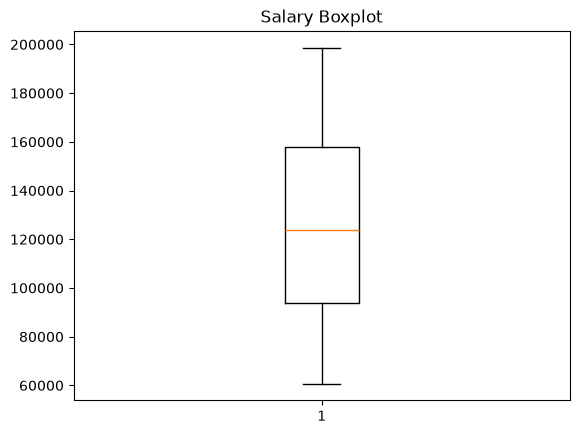

<Axes: xlabel='Age', ylabel='Salary'>

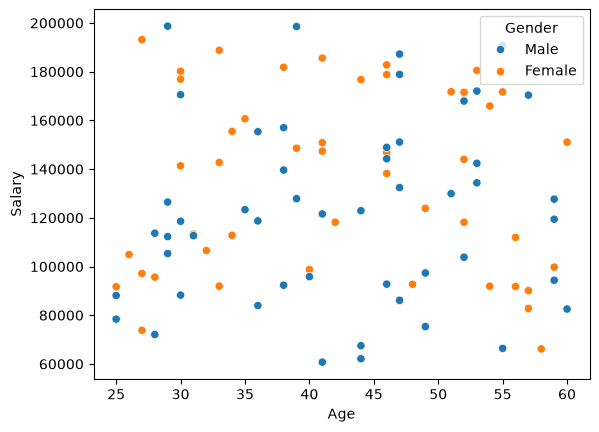

In [9]:
#outlier detection
import seaborn as sns
import matplotlib.pyplot as plt
plt.boxplot(employees['Salary'])
plt.title("Salary Boxplot")
plt.show()
sns.scatterplot(data=employees,x='Age',y='Salary',hue = 'Gender')

In [ ]:
temp_df = pd.pivot_table(employees, index=['Gender','Location'], values= 'Salary')
sns.heatmap(temp_df)

In [ ]:
#correlation between variables
employees[['Age','Salary']].corr()
# employees[['Salary','Location']].corr()


# Interpretation:

# Positive value → increases together
# Negative value → one increases while the other decreases
# Near 0 → little or no linear relationship

In [ ]:
#salary by gender 
print("salary by gender \n", employees.groupby('Gender')['Salary'].mean())

#Age distribution by gender
employees.groupby('Gender')['Age'].mean()

In [ ]:
# Salary by Both Job Title and Gender
print('Understand salary distribution across different job roles.\n',employees.groupby(['JobTitle', 'Gender'])['Salary'].mean())

#Demographic of salary
print("Analyze the demographics of employees, such as gender balance and age distribution.")
print(employees.groupby(['Location','Gender'])['Salary'].mean().sort_values(ascending=False))

#Average salary by gender
employees.groupby([ 'Gender'])['Salary'].mean()

In [ ]:
#pivat Table
print(pd.pivot_table(employees,index=['Location',"Gender"],values='Salary'))


print(pd.pivot_table(employees,index=['JobTitle',"Gender"],values='Salary'))


In [ ]:

# Add Business Insights

# Highest paying job role
pd.pivot_table(employees, index='JobTitle', values='Salary', aggfunc='max').sort_values(by='Salary', ascending=False).head(1) 
# HR Manager -->198686.2

# Lowest paying job role
pd.pivot_table(employees, index='JobTitle', values='Salary', aggfunc='max').sort_values(by='Salary').head(1)
# Software Engineer	--> 171140.65

# Average employee salary
employees['Salary'].mean()
# Mean --> 128117.6209

# Male vs Female employee ratio
employees['Gender'].value_counts().loc['Male']/employees['Gender'].value_counts().loc['Female']
# Ratio = 1.127

# Average salary by gender
pd.pivot_table(employees, index='Gender', values='Salary')

employees.groupby('Gender')['Salary'].mean()
# Female --> 133977.570000
# Male	 --> 122921.062264

# Average salary by job role
pd.pivot_table(employees, index='JobTitle', values='Salary')

employees.groupby('JobTitle')['Salary'].mean()
# Data Scientist    -->	123259.875200
# DevOps Engineer   -->	121788.738333
# HR Manager	    --> 130284.838125
# Project Manager   -->	143201.954000
# Software Engineer -->	123308.163333

# Does salary increase with age?
sns.scatterplot(employees, x='Age',y='Salary')
# By Observing graph we can deduce that there is no such relation between "Age" and "Salary".

# Location with highest salaries
pd.pivot_table(employees, index='Location', values='Salary', aggfunc='sum').sort_values(by='Salary', ascending=False).head(1)

employees.groupby('Location')['Salary'].sum().sort_values(ascending=False).head(1)
# Chicago --> 2985017.14

# HR recommendations for hiring, promotions, and pay equity

,Salary
JobTitle,
Data Scientist,123259.875200
DevOps Engineer,121788.738333
HR Manager,130284.838125
Project Manager,143201.954000
Software Engineer,123308.163333
